In [6]:
import csv
import matplotlib.pyplot as plt

# Put japan.csv in the same folder as your notebook.
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

print(len(data), "prefectures")
print(data[0]["Prefecture"], data[0]["総人口"])

47 prefectures
Hokkaido 5140000


# レポートのタイトル：茨城県と東京都の年齢構成（高齢化率）の比較

担当者：[小泉流駆]
依頼元の組織：茨城県内の某ドラッグストア
読み手：地方の小売店　店長、エリアマネージャー
この組織が知りたいこと：都内の系列店と比べて、うちの店舗はシニアのお客さんが多い気がするが、データでも裏付けられるか？ 今後、都内と同じような若者向けコスメを減らして、介護用品やシニア向け健康食品の棚を増やすべきか？

## 目的
`japan.csv` のデータを用いて、茨城県と東京都の年齢区分別（15歳未満、15～64歳、65歳以上）の人口を抽出し、全体の人口に占める各年代の「割合」を比較します。両都県の総人口には大きな差があるため、実数ではなく100%積み上げ棒グラフを用いて構成比の違いを明確にします。

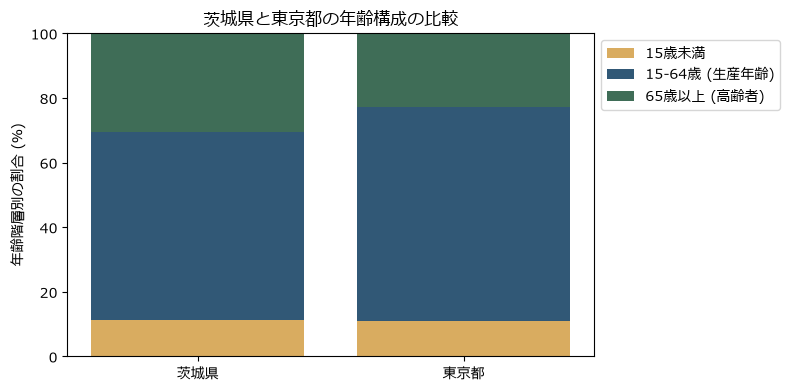

In [7]:
import csv
import matplotlib.pyplot as plt

# グラフのフォントを日本語対応にする設定（Windows向けの標準フォント）
plt.rcParams['font.family'] = 'Meiryo'  # エラーが出る場合は 'MS Gothic' に変えてください

# 1. データの読み込み
with open("japan.csv", encoding="utf-8-sig", newline="") as file:
    data = list(csv.DictReader(file))

# 2. 茨城県と東京都のデータを抽出
chosen = [row for row in data if row["Prefecture"] in ["Ibaraki", "Tokyo"]]
names = [row["都道府県"] for row in chosen]

# 3. 各年齢区分の人数を取得（文字列から数値に変換）
young = [int(row["15歳未満人口"]) for row in chosen]
working = [int(row["15～64歳人口"]) for row in chosen]
older = [int(row["65歳以上人口"]) for row in chosen]

# 4. 構成割合（%）の計算
totals = [young[i] + working[i] + older[i] for i in range(len(chosen))]
young_pct = [young[i] / totals[i] * 100 for i in range(len(chosen))]
working_pct = [working[i] / totals[i] * 100 for i in range(len(chosen))]
older_pct = [older[i] / totals[i] * 100 for i in range(len(chosen))]
base = [young_pct[i] + working_pct[i] for i in range(len(chosen))]

# 5. 100%積み上げ棒グラフの作成（日本語ラベル）
plt.figure(figsize=(8, 4))
plt.bar(names, young_pct, label="15歳未満", color="#d9ac60")
plt.bar(names, working_pct, bottom=young_pct, label="15-64歳 (生産年齢)", color="#315876")
plt.bar(names, older_pct, bottom=base, label="65歳以上 (高齢者)", color="#3f6d57")

plt.ylim(0, 100)
plt.ylabel("年齢階層別の割合 (%)")
plt.title("茨城県と東京都の年齢構成の比較")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 結果と解釈
上記の100%積み上げ棒グラフは、茨城県と東京都の人口をそれぞれ100%としたときの年齢構成比を示しています。

出力された数値とグラフから以下のことがわかりました。
*   **茨城県**の65歳以上の割合（高齢化率）は **30.4%** であり、人口の約3割が高齢者です。
*   一方、**東京都**の65歳以上の割合は **22.8%** であり、茨城県と比較して約7.6ポイント低くなっています。
*   東京都は15〜64歳の生産年齢人口の割合（青色の層）が厚く、地方圏である茨城県の方が相対的に高齢化が進行していることが視覚的にも確認できます。

## 結論
店長・エリアマネージャーへ：
データから明らかなように、茨城県は東京都に比べて市場における「高齢者の密度（割合）」が30%を超えており、顕著に高い状態です。
したがって、都内の店舗で売れているような若者向けのトレンド商品やコスメなどと同じ棚割り（品揃え）を茨城の店舗にそのまま持ち込むのは非効率です。茨城の店舗では、大人用おむつなどの介護用品、健康食品、処方箋の対応など、シニア層に向けた商品・サービスの面積を戦略的に拡大していくことが、地域のニーズに最も合致し、売上アップに繋がると提案します。
（データに関する注意：本分析は授業で提供された `japan.csv` に基づいており、元の統計年次は不明であるため、現在の最新の人口動態と完全に一致しない可能性があります。）